In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import harmonypy as hm

In [2]:
adata = sc.read_h5ad('/Users/penghao.xia/Downloads/siletti_study/HTHtub.h5ad')

In [5]:
print(adata.obs.shape)
adata.obs.columns

(13173, 31)


Index(['roi', 'disease_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'assay_ontology_term_id',
       'sex_ontology_term_id', 'development_stage_ontology_term_id',
       'donor_id', 'suspension_type', 'dissection', 'fraction_mitochondrial',
       'fraction_unspliced', 'cell_cycle_score', 'total_genes', 'total_UMIs',
       'sample_id', 'supercluster_term', 'cluster_id', 'subcluster_id',
       'is_primary_data', 'tissue_type', 'tissue_ontology_term_id',
       'cell_type_ontology_term_id', 'Region', 'cell_type', 'assay', 'disease',
       'sex', 'tissue', 'self_reported_ethnicity', 'development_stage',
       'observation_joinid'],
      dtype='str')

In [9]:
adata.obs['cell_type'].value_counts()

cell_type
neuron                                            9091
mammillary body neuron                            1346
oligodendrocyte precursor cell                     613
oligodendrocyte                                    612
astrocyte                                          378
microglial cell                                    289
caudal ganglionic eminence derived interneuron     256
midbrain-derived inhibitory neuron                 137
committed oligodendrocyte precursor                 89
ependymal cell                                      75
fibroblast                                          60
Lamp5 Lhx6 neuron                                   57
medial ganglionic eminence derived interneuron      42
endothelial cell                                    33
pvalb chandelier GABAergic interneuron              30
T cell                                              22
amygdala excitatory neuron                          17
pericyte                                            10


In [34]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.scrublet(adata, batch_key="sample_id")
adata = adata[~adata.obs['predicted_doublet']].copy()

In [36]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata.layers["counts"][:5, :5]

matrix([[<Compressed Sparse Row sparse matrix of dtype 'float32'
         	with 5 stored elements and shape (5, 5)>              ]],
       dtype=object)

In [37]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

In [29]:
# filter out cell_types with too few cells
cell_types_drop = adata.obs['cell_type'].value_counts()
cell_types_drop = list(cell_types_drop[cell_types_drop < 3].index)
adata = adata[~adata.obs['cell_type'].isin(cell_types_drop)].copy()

In [38]:
sc.tl.rank_genes_groups(
    adata,
    groupby='cell_type',
    method='wilcoxon',
)

In [49]:
results = sc.get.rank_genes_groups_df(
    adata,
    group=None,
    key='rank_genes_groups',
    # pval_cutoff=0.05,  # filter by adjusted p-value
)

In [50]:
results

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,fibroblast,ENSG00000069667,13.194650,3.618324,9.419183e-40,3.195740e-35
1,fibroblast,ENSG00000121440,12.888880,6.581208,5.199339e-38,6.589154e-34
2,fibroblast,ENSG00000196569,12.880096,9.986079,5.826298e-38,6.589154e-34
3,fibroblast,ENSG00000018625,12.771914,7.916357,2.352962e-37,1.995782e-33
4,fibroblast,ENSG00000144642,12.715755,4.128200,4.834193e-37,2.733575e-33
...,...,...,...,...,...,...
678555,Lamp5 Lhx6 neuron,ENSG00000181722,-11.004787,-3.123851,3.623707e-28,2.049085e-25
678556,Lamp5 Lhx6 neuron,ENSG00000184588,-11.008944,-4.676356,3.460379e-28,1.989894e-25
678557,Lamp5 Lhx6 neuron,ENSG00000145416,-11.192903,-4.171216,4.417323e-29,3.058590e-26
678558,Lamp5 Lhx6 neuron,ENSG00000154310,-11.432308,-3.792487,2.883416e-30,2.386062e-27


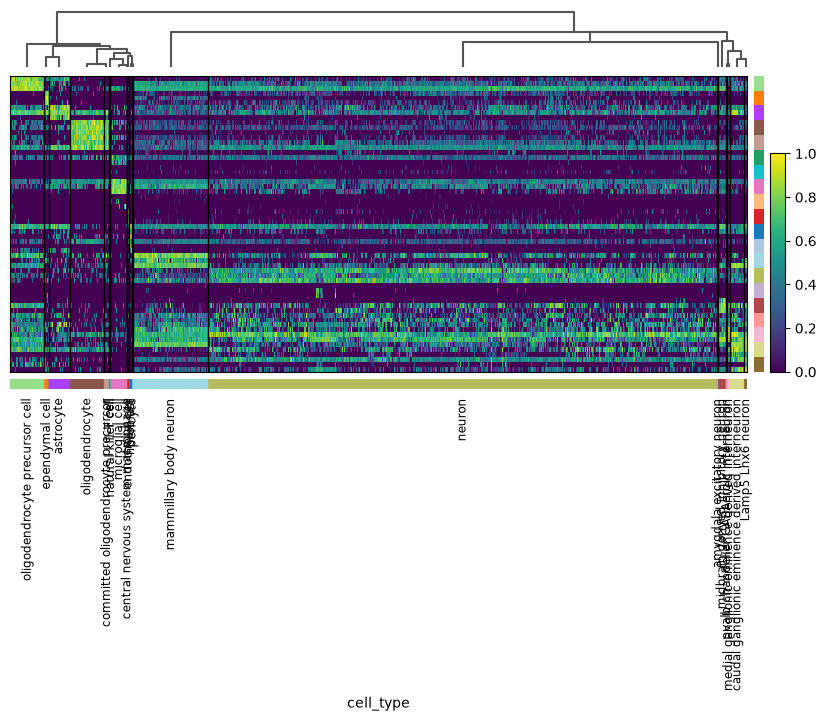

In [48]:
sc.pl.rank_genes_groups_heatmap(
    adata,
    n_genes=3,
    groupby="cell_type",
    standard_scale="var",
    # show_gene_labels=True,
    swap_axes=True,
)